# SentimentForge – Model Benchmarking

## Objective
Compare the computational efficiency of three trained sentiment
classification models.

## Models
1. Logistic Regression – Classical Machine Learning
2. GRU – Recurrent Neural Network
3. DistilBERT – Transformer-based Deep Learning

## Benchmarking metrics
- Model size (MB)
- Average inference latency (milliseconds per review)
- Throughput (reviews per second)
- Test accuracy

## Goal
Identify the best balance between predictive performance
and computational efficiency.

In [8]:
import os
import re
import json
import time
import pickle
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from bs4 import BeautifulSoup
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [6]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
PROJECT_DIR = "/content/drive/MyDrive/SentimentForge"

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
DATA_DIR = os.path.join(PROJECT_DIR, "data")
REPORT_DIR = os.path.join(PROJECT_DIR, "reports")

DATASET_PATH = os.path.join(DATA_DIR, "raw", "IMDB Dataset.csv")

LR_PATH = os.path.join(MODEL_DIR, "logistic_regression.pkl")
TFIDF_PATH = os.path.join(MODEL_DIR, "tfidf_vectorizer.pkl")
GRU_PATH = os.path.join(MODEL_DIR, "gru_epoch5_last.pth")

DISTILBERT_DIR = os.path.join(MODEL_DIR, "distilbert_finetuned")
TOKENIZER_PATH = os.path.join(MODEL_DIR, "tokenizer.pkl")
CONFIG_PATH = os.path.join(MODEL_DIR, "preprocessing_config.json")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Benchmarking device:", device)

Benchmarking device: cpu


In [9]:
lr_model = joblib.load(LR_PATH)
tfidf = joblib.load(TFIDF_PATH)

print("Logistic Regression loaded.")

Logistic Regression loaded.


In [10]:
VOCAB_SIZE = 30000
EMBEDDING_DIM = 128
HIDDEN_DIM = 128

class GRUModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        embedded = self.embedding(x)
        output, hidden = self.gru(embedded)
        last_hidden = hidden[-1]
        prediction = self.fc(last_hidden)

        return prediction.squeeze(1)


gru_model = GRUModel(
    VOCAB_SIZE,
    EMBEDDING_DIM,
    HIDDEN_DIM
)

gru_checkpoint = torch.load(
    GRU_PATH,
    map_location=device,
    weights_only=False
)

gru_model.load_state_dict(gru_checkpoint["model_state_dict"])
gru_model.to(device)
gru_model.eval()

print("GRU model loaded successfully.")

GRU model loaded successfully.


In [11]:
bert_tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_DIR)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    DISTILBERT_DIR
)

bert_model.to(device)
bert_model.eval()

print("DistilBERT loaded successfully.")

Loading weights:   0%|          | 0/104 [00:01<?, ?it/s]

DistilBERT loaded successfully.


In [12]:
df = pd.read_csv(DATASET_PATH)

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

def clean_review(text):
    text = BeautifulSoup(text, "html.parser").get_text(" ")
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-z\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(clean_review)

df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

from sklearn.model_selection import train_test_split

X = df["clean_review"]
y = df["label"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Test reviews:", len(X_test))

Test reviews: 5000


In [13]:
# Logistic Regression input
X_test_tfidf = tfidf.transform(X_test)

# GRU input
with open(TOKENIZER_PATH, "rb") as f:
    sequence_tokenizer = pickle.load(f)

MAX_LEN = config["max_length"]

X_test_sequences = sequence_tokenizer.texts_to_sequences(X_test)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_gru_tensor = torch.tensor(
    X_test_padded,
    dtype=torch.long
)

# DistilBERT input: RAW reviews, not cleaned reviews
raw_test_reviews = df.loc[X_test.index, "review"].tolist()

print("TF-IDF:", X_test_tfidf.shape)
print("GRU:", X_gru_tensor.shape)
print("DistilBERT reviews:", len(raw_test_reviews))

TF-IDF: (5000, 50000)
GRU: torch.Size([5000, 300])
DistilBERT reviews: 5000


In [14]:
def get_file_size(path):
    if os.path.isfile(path):
        return os.path.getsize(path)

    total_size = 0

    for root, dirs, files in os.walk(path):
        for file in files:
            file_path = os.path.join(root, file)
            total_size += os.path.getsize(file_path)

    return total_size


model_sizes = {
    "Logistic Regression": (
        get_file_size(LR_PATH) + get_file_size(TFIDF_PATH)
    ),
    "GRU": get_file_size(GRU_PATH),
    "DistilBERT": get_file_size(DISTILBERT_DIR)
}

size_df = pd.DataFrame([
    {
        "Model": name,
        "Size_MB": size / (1024 ** 2)
    }
    for name, size in model_sizes.items()
])

display(size_df.round(2))

,Model,Size_MB
0,Logistic Regression,2.05
1,GRU,15.03
2,DistilBERT,256.10


In [15]:
def benchmark_logistic(model, vectorizer, reviews, warmup=100, repeats=3):

    sample = reviews.iloc[:warmup]
    sample_tfidf = vectorizer.transform(sample)

    model.predict_proba(sample_tfidf)

    all_times = []

    for _ in range(repeats):
        start = time.perf_counter()

        probabilities = model.predict_proba(
            vectorizer.transform(reviews)
        )

        elapsed = time.perf_counter() - start

        all_times.append(elapsed)

    return {
        "total_time": np.mean(all_times),
        "predictions": probabilities
    }


lr_benchmark = benchmark_logistic(
    lr_model,
    tfidf,
    X_test
)

print("Logistic Regression benchmark completed.")

Logistic Regression benchmark completed.


In [16]:
def benchmark_gru(model, inputs, device, repeats=3):

    model.eval()

    inputs = inputs.to(device)

    # Warmup
    with torch.no_grad():
        model(inputs[:64])

    if device.type == "cuda":
        torch.cuda.synchronize()

    times = []

    for _ in range(repeats):

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        with torch.no_grad():
            logits = model(inputs)

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start
        times.append(elapsed)

    return {
        "total_time": np.mean(times),
        "predictions": torch.sigmoid(logits).cpu().numpy()
    }


gru_benchmark = benchmark_gru(
    gru_model,
    X_gru_tensor,
    device
)

print("GRU benchmark completed.")

GRU benchmark completed.


In [17]:
def benchmark_distilbert(
    model,
    tokenizer,
    reviews,
    device,
    batch_size=8,
    repeats=1
):

    model.eval()

    # Warmup
    warmup_texts = reviews[:batch_size]

    warmup = tokenizer(
        warmup_texts,
        max_length=512,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )

    warmup = {
        key: value.to(device)
        for key, value in warmup.items()
    }

    with torch.no_grad():
        model(**warmup)

    if device.type == "cuda":
        torch.cuda.synchronize()

    all_times = []
    all_probabilities = []

    for repeat in range(repeats):

        probabilities_list = []

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        for i in range(0, len(reviews), batch_size):

            batch_reviews = reviews[i:i + batch_size]

            encoding = tokenizer(
                batch_reviews,
                max_length=512,
                padding="max_length",
                truncation=True,
                return_tensors="pt"
            )

            encoding = {
                key: value.to(device)
                for key, value in encoding.items()
            }

            with torch.no_grad():
                outputs = model(**encoding)

            probabilities = torch.softmax(
                outputs.logits,
                dim=1
            )[:, 1]

            probabilities_list.extend(
                probabilities.cpu().numpy()
            )

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        all_times.append(elapsed)
        all_probabilities = probabilities_list

    return {
        "total_time": np.mean(all_times),
        "probabilities": np.array(all_probabilities)
    }


bert_benchmark = benchmark_distilbert(
    bert_model,
    bert_tokenizer,
    raw_test_reviews,
    device,
    batch_size=8,
    repeats=1
)

print("DistilBERT benchmark completed.")

DistilBERT benchmark completed.


In [18]:
total_reviews = len(X_test)

benchmark_results = []

timings = {
    "Logistic Regression": lr_benchmark["total_time"],
    "GRU": gru_benchmark["total_time"],
    "DistilBERT": bert_benchmark["total_time"]
}

for model_name, total_time in timings.items():

    latency_ms = (total_time / total_reviews) * 1000
    throughput = total_reviews / total_time

    benchmark_results.append({
        "Model": model_name,
        "Total_Time_Seconds": total_time,
        "Latency_ms_per_review": latency_ms,
        "Throughput_reviews_per_second": throughput
    })

benchmark_df = pd.DataFrame(benchmark_results)

display(benchmark_df.round(4))

,Model,Total_Time_Seconds,Latency_ms_per_review,Throughput_reviews_per_second
0,Logistic Regression,2.8058,0.5612,1782.0400
1,GRU,20.4129,4.0826,244.9432
2,DistilBERT,5641.3122,1128.2624,0.8863


In [19]:
accuracy_values = {
    "Logistic Regression": 0.9122,
    "GRU": 0.8884,
    "DistilBERT": 0.9412
}

final_benchmark = benchmark_df.merge(
    size_df,
    on="Model"
)

final_benchmark["Accuracy"] = (
    final_benchmark["Model"].map(accuracy_values)
)

final_benchmark = final_benchmark[
    [
        "Model",
        "Accuracy",
        "Size_MB",
        "Latency_ms_per_review",
        "Throughput_reviews_per_second",
        "Total_Time_Seconds"
    ]
]

display(
    final_benchmark.sort_values(
        "Accuracy",
        ascending=False
    ).round(4)
)

,Model,Accuracy,Size_MB,Latency_ms_per_review,Throughput_reviews_per_second,Total_Time_Seconds
2,DistilBERT,0.9412,256.1047,1128.2624,0.8863,5641.3122
0,Logistic Regression,0.9122,2.0497,0.5612,1782.0400,2.8058
1,GRU,0.8884,15.0300,4.0826,244.9432,20.4129


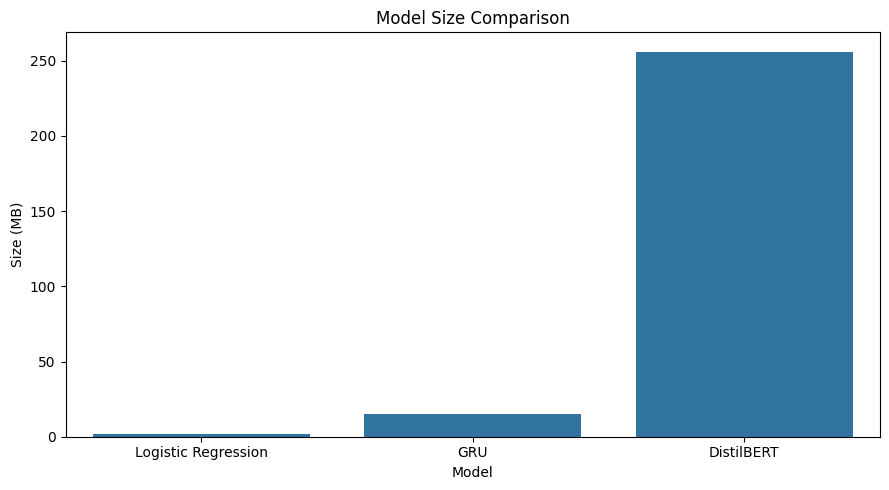

In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_benchmark,
    x="Model",
    y="Size_MB"
)

plt.title("Model Size Comparison")
plt.ylabel("Size (MB)")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

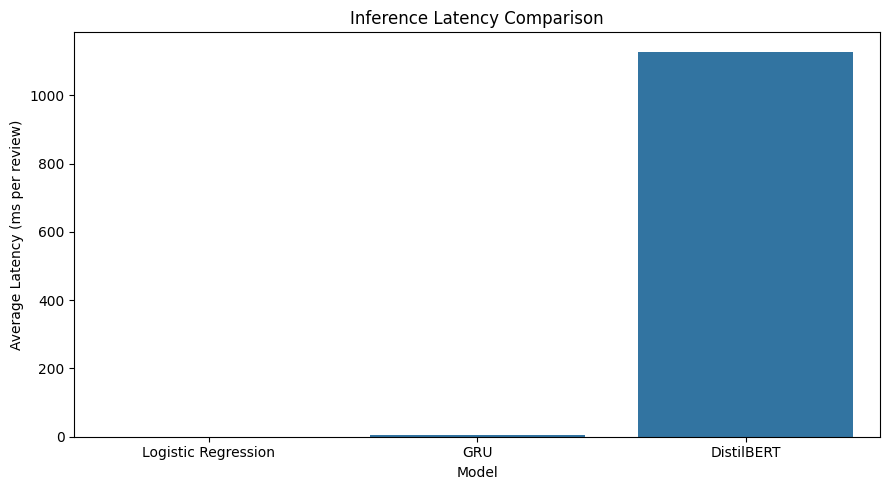

In [21]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_benchmark,
    x="Model",
    y="Latency_ms_per_review"
)

plt.title("Inference Latency Comparison")
plt.ylabel("Average Latency (ms per review)")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

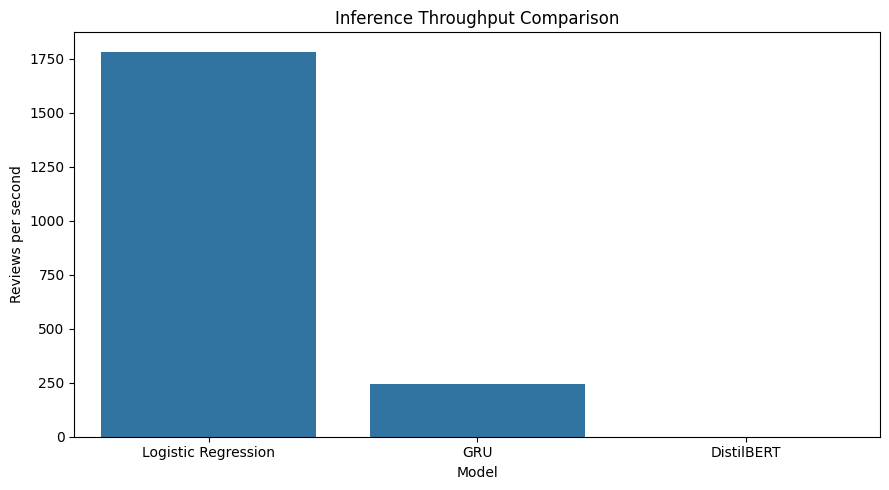

In [22]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_benchmark,
    x="Model",
    y="Throughput_reviews_per_second"
)

plt.title("Inference Throughput Comparison")
plt.ylabel("Reviews per second")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

In [23]:
benchmark_path = os.path.join(
    REPORT_DIR,
    "model_benchmark_comparison.csv"
)

final_benchmark.to_csv(
    benchmark_path,
    index=False
)

print("Benchmark results saved:", benchmark_path)

Benchmark results saved: /content/drive/MyDrive/SentimentForge/reports/model_benchmark_comparison.csv


In [24]:
fastest_model = final_benchmark.loc[
    final_benchmark["Latency_ms_per_review"].idxmin(),
    "Model"
]

smallest_model = final_benchmark.loc[
    final_benchmark["Size_MB"].idxmin(),
    "Model"
]

highest_accuracy_model = final_benchmark.loc[
    final_benchmark["Accuracy"].idxmax(),
    "Model"
]

print("MODEL BENCHMARKING SUMMARY")
print("--------------------------")
print("Fastest model:", fastest_model)
print("Smallest model:", smallest_model)
print("Highest accuracy:", highest_accuracy_model)

print("\nDetailed comparison:")
display(final_benchmark.round(4))

MODEL BENCHMARKING SUMMARY
--------------------------
Fastest model: Logistic Regression
Smallest model: Logistic Regression
Highest accuracy: DistilBERT

Detailed comparison:


,Model,Accuracy,Size_MB,Latency_ms_per_review,Throughput_reviews_per_second,Total_Time_Seconds
0,Logistic Regression,0.9122,2.0497,0.5612,1782.0400,2.8058
1,GRU,0.8884,15.0300,4.0826,244.9432,20.4129
2,DistilBERT,0.9412,256.1047,1128.2624,0.8863,5641.3122
